In [ ]:
import os

# Select the backend before the first PyRITE import; restart to change it.
os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

import pyrite

_ = pyrite.fetch_tables()  # Complete installed tables require no network access.
tables_ready = True

# Angular radiation distributions

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/05-angular-radiation-distributions.py)

Compute an **experimental**, detector-free PXR/CBS energy–angle map
for a finite silicon slab. Directions are signed in the lab **x–z**
plane: 0° is forward, +90° is +x, and ±180° is backward.
The source is **per steradian**, not integrated over an angular bin.

In [ ]:
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics
from pyrite.geometry import Footprint, Slab
from pyrite.radiation import directional_source

beam = Beam(
    energy_keV=30.0,
    transverse=PointSpot(),
    longitudinal=PointBunch(),
    bunch_charge_pc=1.0,
    rep_rate_hz=50_000.0,
)
target = Slab(
    "silicon",
    thickness_ang=1_000.0,
    tilt_deg=30.0,
    footprint=Footprint(5.0, 5.0),
)
numerics = Numerics(
    sampling=FixedSampling(cxr_electrons=512, brem_electrons=512),
    cxr_reflections=CxrReflections(n_families=1),
)

In [ ]:
assert tables_ready  # Wait for reference-table installation before transport.
angles_deg = np.linspace(-180.0, 180.0, 48, endpoint=False)
energies_eV = np.linspace(100.0, 2_000.0, 257)
source = directional_source(
    beam,
    target,
    energy_eV=energies_eV,
    angle_deg=angles_deg,
    numerics=numerics,
    direction_batch=12,
    seed=1,
)
assert source.density.shape == (angles_deg.size, energies_eV.size)

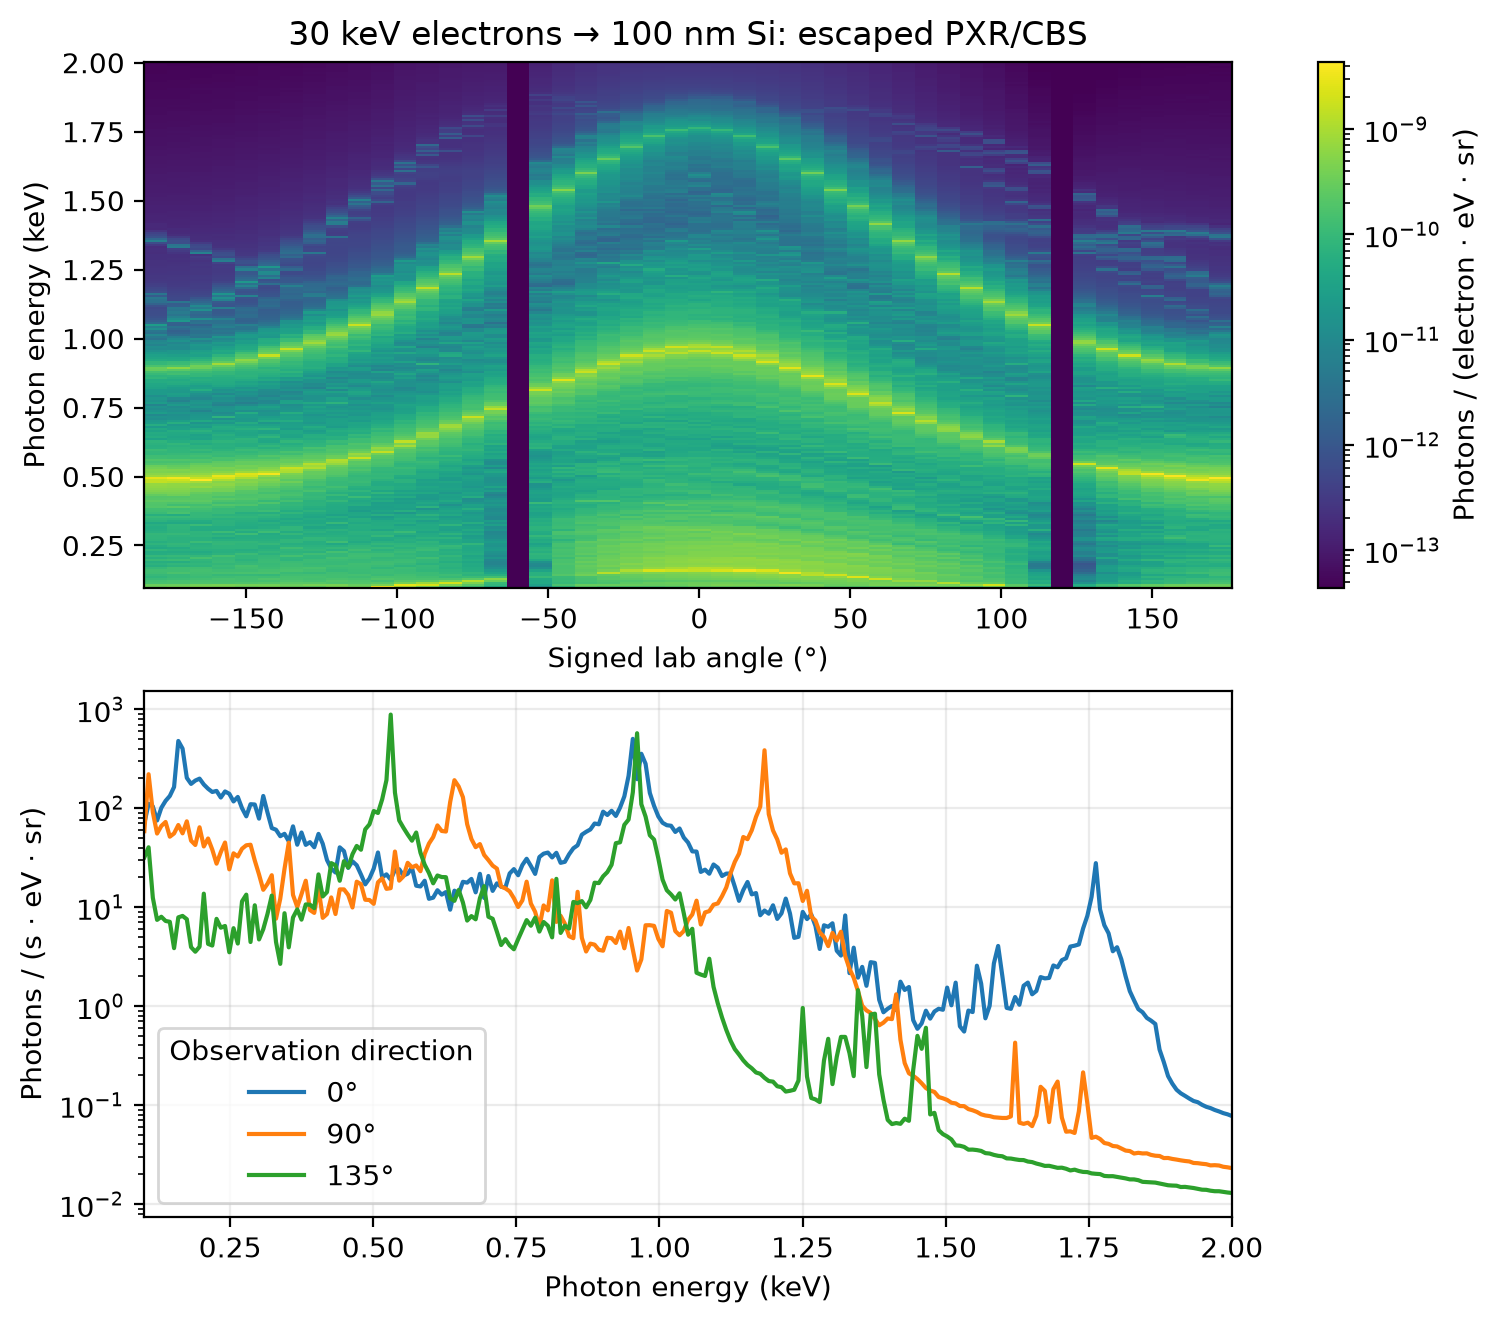

In [ ]:
from matplotlib.colors import LogNorm

# Unsupported directions are NaN, never zero. A finite slab typically has none.
_density = np.where(source.supported[:, None], source.density, np.nan)
_positive = _density[np.isfinite(_density) & (_density > 0)]
if _positive.size == 0:
    raise ValueError("no positive source values; inspect sampling and photon-energy window")
_high = float(np.max(_positive))
_low = _high * 1e-5
_display = np.ma.masked_invalid(np.where(_density > 0, _density, np.nan))

fig_map, (_map_ax, _cut_ax) = plt.subplots(2, 1, figsize=(7.4, 6.5), layout="constrained")
_mesh = _map_ax.pcolormesh(
    source.angle_deg,
    source.energy_eV / 1_000,
    _display.T,
    norm=LogNorm(vmin=_low, vmax=_high),
    shading="auto",
    rasterized=True,
)
fig_map.colorbar(_mesh, ax=_map_ax, label="Photons / (electron · eV · sr)")
_map_ax.set(
    title="30 keV electrons → 100 nm Si: escaped PXR/CBS",
    xlabel="Signed lab angle (°)",
    ylabel="Photon energy (keV)",
)

_rate = source.rate()  # photons / (s · eV · sr), no angular acceptance
for _direction in (0.0, 90.0, 135.0):
    _i = int(np.argmin(np.abs(source.angle_deg - _direction)))
    if source.supported[_i]:
        _cut_ax.plot(source.energy_eV / 1_000, _rate[_i], label=f"{source.angle_deg[_i]:g}°")
_cut_ax.set(
    xlabel="Photon energy (keV)",
    ylabel="Photons / (s · eV · sr)",
    yscale="log",
    xlim=(source.energy_eV[0] / 1_000, source.energy_eV[-1] / 1_000),
)
_cut_ax.legend(title="Observation direction")
_cut_ax.grid(alpha=0.25)
fig_map  # noqa: B018 - captured by marimo

## Interpretation

The map gives **photons / (electron · eV · sr)**; the line cuts use
the configured **50 nA** current to give photons / (s · eV · sr).
Neither includes angular acceptance or detector response. Only PXR/CBS
is calculated here; the energy range is restricted to **100–2,000 eV**.

Unsupported directions are masked, not physical zeros.
Try changing target tilt, history count or grid spacing.
See the [directional-source reference](https://pyrite.readthedocs.io/en/latest/reference/directional-sources.html).

## Continue learning

Next: [From X-rays to detector counts](06-detector-counts.ipynb).
For a task recipe, use [Directional source heatmaps](../../guides/directional-source-heatmap.md).
The [directional source reference](../../reference/directional-sources.md) defines
coordinates, support masks and limits; [spectral observables](../../physics/radiation-physics/spectral-observables.md)
explain density normalization. See [finite-crystal evidence](../../validation/geometry/finite-transverse-crystal.md)
for the escape-geometry checks.

{download}`Download canonical Marimo notebook <../05-angular-radiation-distributions.py>`